<a href="https://colab.research.google.com/github/Deeps-125/market-segmentation-customer-clustering/blob/main/market_segmentation_customer_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset:
     ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957  Graduation         Single  58138.0        0         0   
1  2174        1954  Graduation         Single  46344.0        1         1   
2  4141        1965  Graduation       Together  71613.0        0         0   
3  6182        1984  Graduation       Together  26646.0        1         0   
4  5324        1981         PhD        Married  58293.0        1         0   

  Dt_Customer  Recency  MntWines  ...  NumWebVisitsMonth  AcceptedCmp3  \
0  04-09-2012       58       635  ...                  7             0   
1  08-03-2014       38        11  ...                  5             0   
2  21-08-2013       26       426  ...                  4             0   
3  10-02-2014       26        11  ...                  6             0   
4  19-01-2014       94       173  ...                  5             0   

   AcceptedCmp4  AcceptedCmp5  AcceptedCmp1  AcceptedCmp2  Complain  \
0     

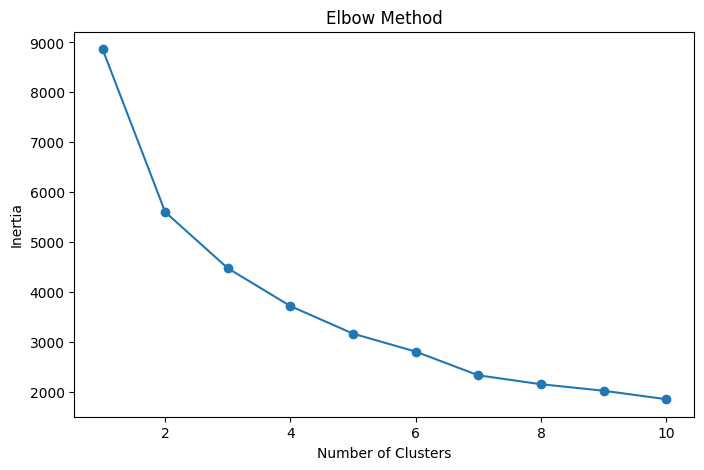


Silhouette Score: 0.3324691225528441

Cluster Centers:
         Age        Income  Total_Children  Total_Spending
0  59.498891  43915.141907        2.110865      220.443459
1  51.979920  78364.319277        0.283133     1437.979920
2  68.510129  59965.834254        0.714549      750.581952
3  47.752762  33684.117403        0.853591      168.755525

Clustered Data:
    Age   Income  Total_Children  Total_Spending  Cluster
0    68  58138.0               0            1617        1
1    71  46344.0               2              27        0
2    60  71613.0               0             776        2
3    41  26646.0               1              53        3
4    44  58293.0               1             422        3
5    58  62513.0               1             716        2
6    54  55635.0               1             590        3
7    40  33454.0               1             169        3
8    51  30351.0               1              46        3
9    75   5648.0               2              49    

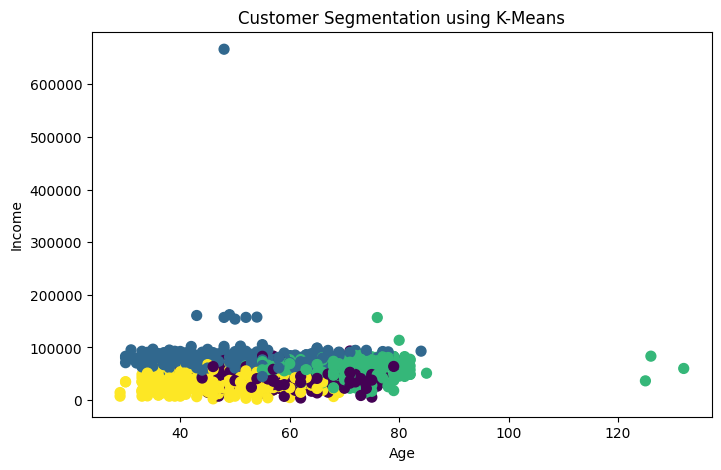

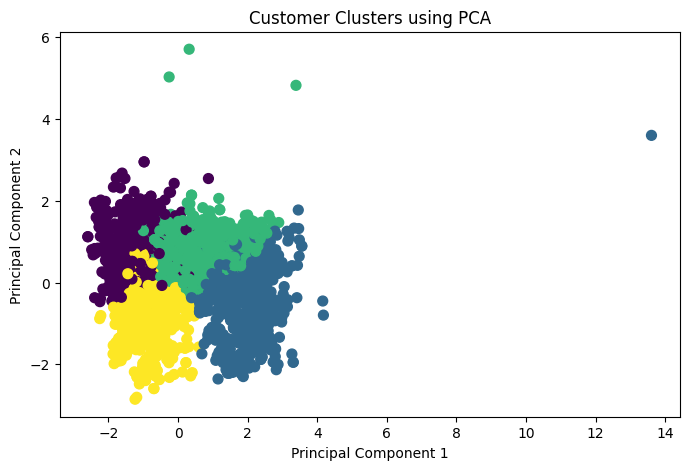

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

df = pd.read_csv("/content/marketing_campaign.csv", sep="\t")

print("Dataset:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumns:")
print(df.columns)

df = df.dropna()

df["Age"] = 2025 - df["Year_Birth"]

df["Total_Children"] = df["Kidhome"] + df["Teenhome"]

df["Total_Spending"] = (
    df["MntWines"] +
    df["MntFruits"] +
    df["MntMeatProducts"] +
    df["MntFishProducts"] +
    df["MntSweetProducts"] +
    df["MntGoldProds"]
)

features = [
    "Age",
    "Income",
    "Total_Children",
    "Total_Spending"
]

X = df[features]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

inertia = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

silhouette = silhouette_score(
    X_scaled,
    df["Cluster"]
)

print("\nSilhouette Score:", silhouette)

centers = scaler.inverse_transform(
    kmeans.cluster_centers_
)

cluster_centers = pd.DataFrame(
    centers,
    columns=features
)

print("\nCluster Centers:")
print(cluster_centers)

print("\nClustered Data:")
print(df[features + ["Cluster"]].head(20))

print("\nCustomers in Each Cluster:")
print(df["Cluster"].value_counts().sort_index())

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Age"],
    df["Income"],
    c=df["Cluster"],
    s=50
)

plt.xlabel("Age")
plt.ylabel("Income")
plt.title("Customer Segmentation using K-Means")
plt.show()

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["Cluster"],
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Clusters using PCA")
plt.show()